# 05 The whole method by hand: 3 farms, 2 channels, 50 days

A small worked example with the same separation as notebooks 01-04: data generation writes measurements and
truth; the test reads only the measurements; scoring reads the truth.

**How to read the tags.** A code cell that uses a result of the paper starts with a comment such as
`# [Thm 2] threshold c_alpha`. The tag names the result; the rest of the line says what the cell does. Numbering
follows the paper: Definition 1 and Lemma 1 (first lags), Theorem 2 (certified links), Proposition 3 (lag scan),
Corollary 4 (channel certificates), Algorithm 1 and the Procedure of Section 3, equations (3) (impulse response),
(4) (residuals), (5) (the statistic), (6) (the threshold), (7) (power) and (8) (measurement duration), and the
conditions C1 (measured innovations) and C2 (predictable regressors and weights) of Theorem 2.

In [1]:
import os, numpy as np, pandas as pd
from math import log, sqrt, ceil
os.makedirs('data/hand', exist_ok=True)
np.set_printoptions(precision=3, suppress=True, linewidth=150)

## Data generation (truth side)
The channels are (perceived scarcity, pumping). The canal innovation enters perceived scarcity, which raises
pumping, and only pumping is copied ($\mathbf H_i$ has one non-zero entry). Farm 2 follows farm 1, farm 3 follows
farm 2, and farm 1 follows farm 3.

In [2]:
# [Model (1)-(2)] the true system
Phi = [np.array([[0.2, 0], [1.0, 0.1]]), np.array([[0.2, 0], [0.8, 0.1]]), np.array([[0.2, 0], [1.2, 0.1]])]
theta = [0.5, 0.6, 0.6]; H = [np.diag([0, x]) for x in theta]
W = np.zeros((3, 3)); W[1, 0] = 1; W[2, 1] = 1; W[0, 2] = 1
gam = np.array([1.0, 0.0]); c_pump = np.array([0.0, 1.0])
Big = np.zeros((6, 6))
for i in range(3):
    Big[2*i:2*i+2, 2*i:2*i+2] = Phi[i]
    for j in range(3):
        if i != j: Big[2*i:2*i+2, 2*j:2*j+2] = W[i, j] * H[i]
G = np.zeros((6, 3))
for j in range(3): G[2*j:2*j+2, j] = gam
print(Big)
print('spectral radius:', round(max(abs(np.linalg.eigvals(Big))), 3))

[[0.2 0.  0.  0.  0.  0. ]
 [1.  0.1 0.  0.  0.  0.5]
 [0.  0.  0.2 0.  0.  0. ]
 [0.  0.6 0.8 0.1 0.  0. ]
 [0.  0.  0.  0.  0.2 0. ]
 [0.  0.  0.  0.6 1.2 0.1]]
spectral radius: 0.665


In [3]:
# simulate 50 event days; the residual is pumping minus the response to the farm's own excitation
def h(i, j, tau):
    """[eq. (3)] impulse response from farm j's input to farm i's pumping at lag tau (truth side)."""
    return c_pump @ np.linalg.matrix_power(Big, tau - 1)[2*i:2*i+2, :] @ G[:, j]
rng = np.random.default_rng(20); n_ev = 50; burn = 60; T = burn + n_ev + 8
e = rng.choice([-1.0, 1.0], size=(T, 3)); x = np.zeros(6); Y = np.zeros((T, 3))
for k in range(T):
    Y[k] = [c_pump @ x[2*i:2*i+2] for i in range(3)]
    x = Big @ x + G @ e[k] + 0.1 * rng.standard_normal(6)
Y += 0.05 * rng.standard_normal(Y.shape)
Res = Y.copy()
for i in range(3):
    for s in range(1, 7): Res[s:, i] -= h(i, i, s) * e[:-s, i]
k0 = burn - 1
m = e[k0+1:k0+n_ev+1]; yt = np.round(Res[k0+1:k0+n_ev+5], 2)
np.savez('data/hand/measurements.npz', m=m, ytilde=yt)      # what the test sees
np.savez('data/hand/truth.npz', W=W, Big=Big)               # what only scoring sees
print('measurements:', m.shape, yt.shape)

measurements: (50, 3) (54, 3)


## The test (reads only `data/hand/measurements.npz`)

In [4]:
z = np.load('data/hand/measurements.npz'); m, yt = z['m'], z['ytilde']; n = m.shape[0]
# [Def 1, Lemma 1] from the sketch: one step to enter perceived scarcity, one internal step to pumping, one to cross
TAU = 3
# [Thm 2, eq. (6)] threshold for n_p = 6 pairs, alpha = 0.1, b_hi / b_lo = 1e4
def threshold(n_p, alpha, ratio=1e4):
    best = None
    for kappa in np.linspace(1.02, 1.6, 59):
        n_kappa = ceil(log(ratio) / log(kappa)); c = sqrt(2 * kappa * log(2 * n_p * n_kappa / alpha))
        if best is None or c < best[0]: best = (c, kappa, n_kappa)
    return best
c, kappa, n_kappa = threshold(6, 0.1)
print(f'kappa={kappa:.2f}  n_kappa={n_kappa}  c_alpha={c:.2f};  fewest events that can be reported: c^2 = {c*c:.1f}')
def Z(j, i, tau, Y=yt):
    D = m[:, j] * Y[tau:tau + n, i]; return D.sum(), (D**2).sum(), D.sum() / np.sqrt((D**2).sum())
rows = []
for j in range(3):
    for i in range(3):
        if i == j: continue
        A, V2, z_ = Z(j, i, TAU)
        rows.append(dict(pair=f'{j+1}->{i+1}', A=round(A, 2), V2=round(V2, 4), Z=round(z_, 2), reported=abs(z_) >= c,
                         p_value=min(1, 2 * 6 * n_kappa * np.exp(-z_**2 / (2 * kappa)))))
pd.DataFrame(rows)

kappa=1.11  n_kappa=89  c_alpha=4.54;  fewest events that can be reported: c^2 = 20.6


,pair,A,V2,Z,reported,p_value
0,1->2,28.75,31.1779,5.15,True,0.006954
1,1->3,-2.45,24.7837,-0.49,False,1.000000
2,2->1,-2.00,25.2578,-0.40,False,1.000000
3,2->3,26.35,24.7837,5.29,True,0.003532
4,3->1,26.88,25.2578,5.35,True,0.002706
5,3->2,-0.93,31.1779,-0.17,False,1.000000


In [5]:
# [Prop 3] lag scan over lags 1..4, each at level alpha / 4
c4 = threshold(6, 0.1 / 4)[0]
tab = pd.DataFrame({f'{j+1}->{i+1}': [round(Z(j, i, t)[2], 2) for t in (1, 2, 3, 4)]
                    for j in range(3) for i in range(3) if i != j}, index=[f'tau={t}' for t in (1, 2, 3, 4)]).T
print(f'threshold per lag: {c4:.2f}'); tab

threshold per lag: 4.86


,tau=1,tau=2,tau=3,tau=4
1->2,0.56,1.19,5.15,3.13
1->3,-1.05,0.86,-0.49,2.97
2->1,0.21,-0.62,-0.40,2.84
2->3,-0.93,-0.57,5.29,0.51
3->1,-0.11,-1.31,5.35,2.38
3->2,-0.03,-1.29,-0.17,2.69


## Scoring (reads the truth)

In [6]:
t = np.load('data/hand/truth.npz')
reported = {r['pair'] for r in rows if r['reported']}
true = {f'{j+1}->{i+1}' for i in range(3) for j in range(3) if t['W'][i, j] > 0}
print('reported:', sorted(reported)); print('true    :', sorted(true)); print('exact match:', reported == true)
# [eqs. (7)-(8)] with innovations of +-1 (sigma_e = lambda = K = 1, r = 1): mu = sqrt(n) h / sigma_ytilde,
# estimated as h n / sqrt(V^2); measurement duration for 90% power: (c_alpha + z_0.1)^2 V^2 / (n h^2)
for (j, i) in [(0, 1), (1, 2), (2, 0)]:
    g = h(i, j, 3); A, V2, z_ = Z(j, i, 3)
    print(f'{j+1}->{i+1}: h={g:.2f}  predicted mu={g*n/np.sqrt(V2):.2f}  observed Z={z_:.2f}  '
          f'events for 90% power={(c+1.2816)**2*(V2/n)/g**2:.0f}')

reported: ['1->2', '2->3', '3->1']
true    : ['1->2', '2->3', '3->1']
exact match: True
1->2: h=0.60  predicted mu=5.37  observed Z=5.15  events for 90% power=59
2->3: h=0.48  predicted mu=4.82  observed Z=5.29  events for 90% power=73
3->1: h=0.60  predicted mu=5.97  observed Z=5.35  events for 90% power=48


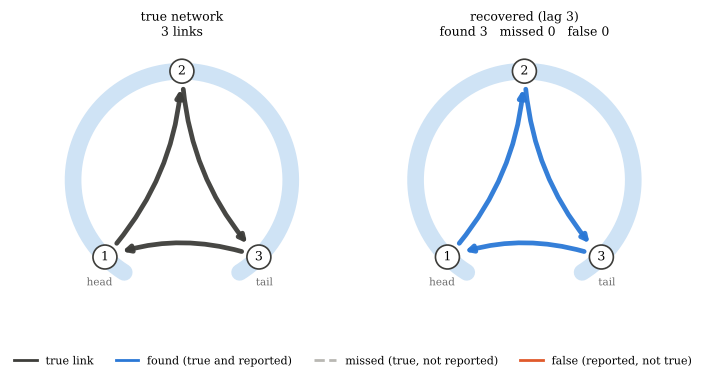

In [7]:
# the true and the recovered network (3 farms)
import sys; sys.path.insert(0, 'lib'); import netplot as NP
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif'})
W_hat = np.zeros((3, 3), bool)
for r in rows:
    if r['reported']:
        j, i = [int(x) - 1 for x in r['pair'].split('->')]; W_hat[i, j] = True
fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
NP.draw_network(ax[0], t['W'], None, 'true network')
NP.draw_network(ax[1], t['W'], W_hat, 'recovered (lag 3)')
NP.network_legend(fig); fig.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()